<a href="https://colab.research.google.com/github/MohamedAamer01/otto-recommender-sys/blob/main/notebooks/08_final_b4star.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Environnement**

In [7]:
import os, sys, time, pickle
import numpy as np, pandas as pd
from google.colab import drive, userdata
drive.mount("/content/drive")

BASE    = "/content/drive/MyDrive/OTTO_Recommender_System"
NPY_DIR = f"{BASE}/data/processed"
SRC     = f"{BASE}/src"
os.makedirs(SRC, exist_ok=True)
sys.path.insert(0, SRC)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Ecriture du modele

In [8]:
%%writefile /content/drive/MyDrive/OTTO_Recommender_System/src/otto_core.py
"""otto_core.py - fonctions essentielles du projet OTTO (testées contre un calcul brut ou la version notebook)."""
import time
import numpy as np

WEIGHTS = {"clicks": 0.10, "carts": 0.30, "orders": 0.60}
TYPE2ID = {"clicks": 0, "carts": 1, "orders": 2}


# ---------------------------------------------------------------- co-visitation
def covisit_block(aid_b, ts_b, sizes_b, K, window, tmax=None):
    """Paires ordonnées (i, j) des K derniers événements (ts < tmax) de chaque session.
    Retourne (clés triées, compteurs). clé = i * 2**21 + j."""
    S = len(sizes_b)
    sess = np.repeat(np.arange(S), sizes_b)
    if tmax is not None:                                   # anti-fuite : on retire les événements >= tmax
        keep = ts_b < tmax
        sess, aid_b, ts_b = sess[keep], aid_b[keep], ts_b[keep]
    sz = np.bincount(sess, minlength=S)
    starts = np.cumsum(sz) - sz
    pos_end = sz[sess] - 1 - (np.arange(len(sess)) - starts[sess])      # 0 = dernier événement
    sel = pos_end < K
    A = np.full((S, K), -1, dtype=np.int64)
    Tm = np.zeros((S, K), dtype=np.int64)
    A[sess[sel], pos_end[sel]] = aid_b[sel]
    Tm[sess[sel], pos_end[sel]] = ts_b[sel]
    ai, aj = A[:, :, None], A[:, None, :]
    ok = (ai >= 0) & (aj >= 0) & (ai != aj) & (np.abs(Tm[:, :, None] - Tm[:, None, :]) <= window)
    keys = (np.broadcast_to(ai, ok.shape)[ok] << 21) | np.broadcast_to(aj, ok.shape)[ok]
    return np.unique(keys, return_counts=True)


def merge(parts):
    k = np.concatenate([p[0] for p in parts]); c = np.concatenate([p[1] for p in parts])
    u, inv = np.unique(k, return_inverse=True)
    return u, np.bincount(inv, weights=c).astype(np.int64)


def build_topn(aid_arr, ts_arr, sizes_arr, cum, n_items, K=10, window=86400, tmax=None,
               N=50, P=4, BLOCK=50_000):
    """Table des N meilleurs voisins par article : nbr_j[i] = voisins, nbr_c[i] = compteurs."""
    nbr_j = np.full((n_items, N), -1, dtype=np.int32)
    nbr_c = np.zeros((n_items, N), dtype=np.float32)
    n_sess, MASK = len(sizes_arr), (1 << 21) - 1
    for p in range(P):
        t0, parts = time.time(), []
        for s in range(0, n_sess, BLOCK):
            e = min(s + BLOCK, n_sess); a, z = cum[s], cum[e]
            k, c = covisit_block(aid_arr[a:z], ts_arr[a:z], sizes_arr[s:e], K, window, tmax)
            m = ((k >> 21) % P) == p
            parts.append((k[m], c[m]))
            if len(parts) >= 20:
                parts = [merge(parts)]
        keys, counts = merge(parts)
        i = (keys >> 21).astype(np.int64); j = (keys & MASK).astype(np.int32)
        order = np.lexsort((-counts, i))
        i, j, counts = i[order], j[order], counts[order]
        rank = np.arange(len(i)) - np.searchsorted(i, i, side="left")
        keep = rank < N
        nbr_j[i[keep], rank[keep]] = j[keep]
        nbr_c[i[keep], rank[keep]] = counts[keep]
        print(f"partition {p+1}/{P} : {len(keys):,} paires distinctes | {time.time()-t0:.0f}s")
        del keys, counts, i, j, order, parts
    return nbr_j, nbr_c


# ---------------------------------------------------------------- popularité et listes
def top_lists(aid_arr, type_arr, n_items, mask=None, k=40):
    """Top-k articles par type (clicks, carts, orders), sur les événements où mask est vrai."""
    m = np.ones(len(aid_arr), bool) if mask is None else mask
    return {t: np.argsort(-np.bincount(aid_arr[m & (type_arr == i)], minlength=n_items),
                          kind="stable")[:k].tolist() for t, i in TYPE2ID.items()}


def topup(base, top, n=20):
    lst = list(base); s = set(lst)
    for x in top:
        if len(lst) == n: break
        if x not in s: lst.append(x)
    return lst


def lists_b4star(seen, tops, nj, nc, n_seed=10, gamma=0.5, row_norm=True, n=20):
    """B4* : articles de la session (récents d'abord), puis candidats de co-visitation, puis popularité par type.
    seen : articles distincts de la session, du plus récent au plus ancien."""
    base = seen[:n]; sset = set(base)
    if len(base) < n:
        sd = np.asarray(seen[:n_seed])
        cs = nc[sd].astype(np.float64)
        if row_norm:
            cs = cs / np.maximum(cs.sum(axis=1, keepdims=True), 1)
        cs = cs * (gamma ** np.arange(len(sd)))[:, None]
        js = nj[sd].ravel(); cs = cs.ravel(); m = js >= 0
        if m.any():
            u, inv = np.unique(js[m], return_inverse=True)
            sc = np.bincount(inv, weights=cs[m])
            order = np.argsort(-sc, kind="stable")
            base = base + [int(x) for x in u[order] if int(x) not in sset][:n - len(base)]
    return {t: topup(base, tops[t], n) for t in WEIGHTS}


def write_submission(path, ids, t_aid, t_size, tops, nj, nc, **kw):
    """Écrit le fichier de soumission en flux : 3 lignes par session (clicks, carts, orders)."""
    off = np.concatenate([[0], np.cumsum(t_size, dtype=np.int64)])
    t0 = time.time()
    with open(path, "w") as f:
        f.write("session_type,labels\n")
        for i in range(len(ids)):
            seen = list(dict.fromkeys(map(int, t_aid[off[i]:off[i + 1]][::-1])))
            r = lists_b4star(seen, tops, nj, nc, **kw)
            for t in WEIGHTS:
                f.write(f"{ids[i]}_{t},{' '.join(map(str, r[t]))}\n")
            if (i + 1) % 500_000 == 0:
                print(f"{i+1:,} sessions ({time.time()-t0:.0f}s)")


# ---------------------------------------------------------------- validation et métrique
def split_labels(suf_aid, suf_type):
    clicks = suf_aid[suf_type == 0]
    return {"clicks": {int(clicks[0])} if len(clicks) else set(),
            "carts": set(map(int, suf_aid[suf_type == 1])),
            "orders": set(map(int, suf_aid[suf_type == 2]))}


def per_session(make, GT, k=20):
    sids = list(GT)
    H = {t: np.zeros(len(sids)) for t in WEIGHTS}; D = {t: np.zeros(len(sids)) for t in WEIGHTS}
    for i, sid in enumerate(sids):
        lists = make(sid)
        for t in WEIGHTS:
            gt = GT[sid][t]
            if gt:
                H[t][i] = len(set(lists[t][:k]) & gt); D[t][i] = min(k, len(gt))
    return H, D


def score_from(H, D, idx=None):
    out = {}
    for t in WEIGHTS:
        h = H[t] if idx is None else H[t][idx]; d = D[t] if idx is None else D[t][idx]
        out[t] = h.sum() / d.sum()
    out["score"] = sum(WEIGHTS[t] * out[t] for t in WEIGHTS)
    return out


def boot_diff_all(HA, HB, D, B=100, seed=0):
    r = np.random.default_rng(seed); n = len(next(iter(D.values())))
    diffs = {k: [] for k in list(WEIGHTS) + ["score"]}
    for _ in range(B):
        idx = r.integers(0, n, n); a = score_from(HA, D, idx); b = score_from(HB, D, idx)
        for k in diffs: diffs[k].append(b[k] - a[k])
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in diffs.items()}

Overwriting /content/drive/MyDrive/OTTO_Recommender_System/src/otto_core.py


**test unitaire du module**

In [9]:
import importlib, tempfile
from collections import Counter
import otto_core; importlib.reload(otto_core)
from otto_core import *

rng = np.random.default_rng(3)
S = 600; sizes = rng.integers(2, 25, S).astype(np.int32); Nn = int(sizes.sum())
aid = rng.integers(0, 60, Nn).astype(np.int32)
ts  = np.concatenate([np.sort(rng.integers(0, 300, n)) for n in sizes]).astype(np.int32)
ty  = rng.choice([0, 1, 2], Nn, p=[.9, .08, .02]).astype(np.int8)
cum_t = np.concatenate([[0], np.cumsum(sizes, dtype=np.int64)])

def brute(K, W, tm):
    C, p = Counter(), 0
    for n in sizes:
        a, t = aid[p:p+n], ts[p:p+n]; p += n
        m = t < tm; a, t = a[m][-K:], t[m][-K:]
        for x in range(len(a)):
            for y in range(len(a)):
                if x != y and a[x] != a[y] and abs(int(t[x]) - int(t[y])) <= W:
                    C[(int(a[x]), int(a[y]))] += 1
    return C

k, c = covisit_block(aid, ts, sizes, 8, 100, 250)
got = {(int(x >> 21), int(x & ((1 << 21) - 1))): int(v) for x, v in zip(k, c)}
assert got == dict(brute(8, 100, 250)); print("covisit_block conforme au calcul brut")

a1 = build_topn(aid, ts, sizes, cum_t, 60, K=8, window=100, tmax=250, N=5, P=4, BLOCK=100)
a2 = build_topn(aid, ts, sizes, cum_t, 60, K=8, window=100, tmax=250, N=5, P=1, BLOCK=100)
assert np.array_equal(a1[0], a2[0]) and np.allclose(a1[1], a2[1]); print("partitions conformes")

tops_t = top_lists(aid, ty, 60, ts < 250)
ids = np.arange(900, 905); t_size = np.array([2, 3, 1, 4, 30], dtype=np.int32)
t_aid = rng.integers(0, 60, t_size.sum()).astype(np.int32)
path = tempfile.mktemp(suffix=".csv"); write_submission(path, ids, t_aid, t_size, tops_t, *a1)
back = pd.read_csv(path); assert back.shape == (15, 2)
assert back["labels"].map(lambda s: len(s.split()) == 20 and len(set(s.split())) == 20).all()
print("fichier de soumission conforme")

GT_t = {s: split_labels(aid[cum_t[s]+1:cum_t[s+1]], ty[cum_t[s]+1:cum_t[s+1]]) for s in range(50)}
H_, D_ = per_session(lambda s: {t: list(GT_t[s][t])[:20] for t in WEIGHTS}, GT_t)
assert abs(score_from(H_, D_)["score"] - 1) < 1e-12; print("oracle = 1.0")

covisit_block conforme au calcul brut
partition 1/4 : 883 paires distinctes | 0s
partition 2/4 : 880 paires distinctes | 0s
partition 3/4 : 879 paires distinctes | 0s
partition 4/4 : 884 paires distinctes | 0s
partition 1/1 : 3,526 paires distinctes | 0s
partitions conformes
fichier de soumission conforme
oracle = 1.0


**chargement, et non-régression sur le dev**

In [10]:
N, N_SESSIONS = 216_716_096, 12_899_779
aid_arr   = np.load(f"{NPY_DIR}/aid.npy");  ts_arr   = np.load(f"{NPY_DIR}/ts.npy")
type_arr  = np.load(f"{NPY_DIR}/type.npy"); sizes_arr = np.load(f"{NPY_DIR}/sizes.npy")
assert len(aid_arr) == N and len(sizes_arr) == N_SESSIONS and sizes_arr.sum() == N
cum = np.concatenate([[0], np.cumsum(sizes_arr, dtype=np.int64)])
n_items = int(aid_arr.max()) + 1

with open(f"{NPY_DIR}/dev_validation.pkl", "rb") as f:
    dev = pickle.load(f)
T, GT, prefix_len = dev["T"], dev["GT"], dev["prefix_len"]
nj = np.load(f"{NPY_DIR}/covisit_K10_T_nbr_j.npy"); nc = np.load(f"{NPY_DIR}/covisit_K10_T_nbr_c.npy")
tops_T = top_lists(aid_arr, type_arr, n_items, ts_arr < T)

def seen_dev(sid):
    a, k = cum[sid], prefix_len[sid]
    return list(dict.fromkeys(map(int, aid_arr[a:a + k][::-1])))

H, D = per_session(lambda s: lists_b4star(seen_dev(s), tops_T, nj, nc), GT)
r = score_from(H, D)
print({k: round(v, 4) for k, v in r.items()}, "(attendu : score 0.5497)")
assert abs(r["score"] - 0.5497) < 5e-4, "le module ne redonne pas B4* : ne pas soumettre"

{'clicks': np.float64(0.5134), 'carts': np.float64(0.4042), 'orders': np.float64(0.6285), 'score': np.float64(0.5497)} (attendu : score 0.5497)


**Table finale sur tout le train, et popularité**

In [11]:
t0 = time.time()
nbr_j_all, nbr_c_all = build_topn(aid_arr, ts_arr, sizes_arr, cum, n_items,
                                  K=10, window=86400, tmax=None, N=50, P=4)
print(f"Construction : {(time.time()-t0)/60:.1f} min")
print(f"Articles avec au moins 1 voisin : {(nbr_j_all[:, 0] >= 0).mean()*100:.1f} % (avant T : 91.5 %)")
np.save(f"{NPY_DIR}/covisit_K10_ALL_nbr_j.npy", nbr_j_all)
np.save(f"{NPY_DIR}/covisit_K10_ALL_nbr_c.npy", nbr_c_all)

tops_all = top_lists(aid_arr, type_arr, n_items)                       # popularité : tout le train
print("Top-5 orders :", tops_all["orders"][:5])

partition 1/4 : 31,642,272 paires distinctes | 79s
partition 2/4 : 31,531,515 paires distinctes | 78s
partition 3/4 : 31,589,946 paires distinctes | 78s
partition 4/4 : 31,407,527 paires distinctes | 83s
Construction : 5.3 min
Articles avec au moins 1 voisin : 95.3 % (avant T : 91.5 %)
Top-5 orders : [231487, 166037, 1733943, 1445562, 1022566]


# **données de test, vérifications**

In [12]:
import zipfile
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
DATA_DIR = "/content/otto_data"; os.makedirs(DATA_DIR, exist_ok=True)
!pip install -q --upgrade kaggle
!kaggle competitions download -c otto-recommender-system -f sample_submission.csv -p /content/otto_data
zp = f"{DATA_DIR}/sample_submission.csv.zip"
if os.path.exists(zp):
    with zipfile.ZipFile(zp) as z: z.extractall(DATA_DIR)

t_aid  = np.load(f"{NPY_DIR}/test_aid.npy")
t_size = np.load(f"{NPY_DIR}/test_sizes.npy")
ids    = np.load(f"{NPY_DIR}/test_session_ids.npy")
sample = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

assert len(t_size) == len(ids) == 1_671_803 and t_size.sum() == len(t_aid) == 6_928_123
assert t_aid.max() < n_items                                           # tous les aid du test existent dans le train
first = sample["session_type"].iloc[::3].str.split("_").str[0].astype("int64").values
assert np.array_equal(first, ids), "ordre différent de sample_submission"
print("Test et ordre des identifiants : OK |", len(sample), "lignes attendues")

100% 12.6M/12.6M [00:02<00:00, 6.57MB/s]

Test et ordre des identifiants : OK | 5015409 lignes attendues


**génération, vérification du format**

In [13]:
import shutil
sub_path = "/content/submission_B4star.csv"
write_submission(sub_path, ids, t_aid, t_size, tops_all, nbr_j_all, nbr_c_all)
print(f"Taille : {os.path.getsize(sub_path)/1e6:.0f} MB")

back = pd.read_csv(sub_path, usecols=["session_type"])
assert back["session_type"].equals(sample["session_type"]), "ordre ou clés différents"
chk = pd.read_csv(sub_path, nrows=300_000)
assert chk["labels"].map(lambda s: len(s.split()) == 20 and len(set(s.split())) == 20).all()
print("Format OK :", back.shape[0], "lignes (attendu 5 015 409)")

os.makedirs(f"{BASE}/submissions", exist_ok=True)
shutil.copy(sub_path, f"{BASE}/submissions/submission_B4star.csv")

500,000 sessions (87s)
1,000,000 sessions (177s)
1,500,000 sessions (253s)
Taille : 818 MB
Format OK : 5015409 lignes (attendu 5 015 409)


'/content/drive/MyDrive/OTTO_Recommender_System/submissions/submission_B4star.csv'

**Soumission**

In [14]:
!kaggle competitions submit -c otto-recommender-system -f /content/submission_B4star.csv -m "B4*: session + covisit (K=10, 24h, top-50, gamma 0.5, row-norm) + popularity"

100% 780M/780M [00:37<00:00, 21.6MB/s]
Submission ref: 58888258
99 submissions remaining today.
Successfully submitted to OTTO – Multi-Objective Recommender System

In [15]:
!kaggle competitions submissions -c otto-recommender-system

     ref  fileName               date                        description                                                                   status                     publicScore  privateScore  
--------  ---------------------  --------------------------  ----------------------------------------------------------------------------  -------------------------  -----------  ------------  
58888258  submission_B4star.csv  2026-11-25 12:53:53.437000  B4*: session + covisit (K=10, 24h, top-50, gamma 0.5, row-norm) + popularity  SubmissionStatus.PENDING                              
58798412  sub_B_robust.csv       2026-11-23 22:51:25.900000  B4* clicks+carts, orders reranker 15 features no scale (B)                    SubmissionStatus.COMPLETE  0.57207      0.57203       
58798409  sub_A_full.csv         2026-11-23 22:51:13.133000  B4* clicks+carts, orders reranker 18 features (A)                             SubmissionStatus.COMPLETE  0.57597      0.57566       
58796275  submission_B4star.cs

# **Le journal des resultats**

In [16]:
RESULTS_PATH = f"{BASE}/reports/results.csv"
def log_result(name, r, notes="", split="dev300k", path=RESULTS_PATH):
    row = {"model": name, "split": split, "clicks": round(float(r["clicks"]), 4), "carts": round(float(r["carts"]), 4),
           "orders": round(float(r["orders"]), 4), "score": round(float(r["score"]), 5), "notes": notes}
    new = pd.DataFrame([row])
    if os.path.exists(path):
        old = pd.read_csv(path)
        old = old[~((old["model"] == name) & (old["split"] == split))]
        new = pd.concat([old, new], ignore_index=True)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    new.to_csv(path, index=False)
    return new

nan = float("nan")
for split, s in [("kaggle_public", 0.56353), ("kaggle_private", 0.56271)]:
    log_result("B4* γ=0.5 + normalisation", dict(clicks=nan, carts=nan, orders=nan, score=s),
               "soumission Kaggle (tardive), table sur tout le train", split=split)
display(pd.read_csv(RESULTS_PATH).tail(4))

,model,split,clicks,carts,orders,score,notes
15,7 classeur 3 types (18 variables),dev300k,0.5094,0.3954,0.6535,0.56167,NÉGATIF pour carts (-0.0088) et clicks (-0.004...
16,7b classeur orders sans variables d'échelle,dev300k,0.5134,0.4042,0.6477,0.56120,"15 variables (sans raw_sum, logpop, logpop_t) ..."
17,B4* γ=0.5 + normalisation,kaggle_public,NaN,NaN,NaN,0.56353,"soumission Kaggle (tardive), table sur tout le..."
18,B4* γ=0.5 + normalisation,kaggle_private,NaN,NaN,NaN,0.56271,"soumission Kaggle (tardive), table sur tout le..."


# **Cellules du pilote**

module de classement

In [17]:
%%writefile /content/drive/MyDrive/OTTO_Recommender_System/src/otto_rank.py
"""otto_rank.py - classeur appris (reranker) : variables par couple (session, candidat), jeux d'entraînement, évaluation."""
import numpy as np
from otto_core import WEIGHTS, TYPE2ID, split_labels

FEATS = ["gen_score", "raw_sum", "n_seeds", "best_seed", "in_session", "n_events", "last_pos",
         "n_click", "n_cart", "n_order", "age_min", "logpop", "logpop_t", "top_rank",
         "prefix_len", "n_distinct", "last_type", "span_min"]


def make_ctx(aid_arr, ts_arr, type_arr, cum, n_items, nj, nc, tops, pop_mask=None):
    """Regroupe tout ce dont cand_features a besoin. pop_mask : événements utilisés pour la popularité (ts < T)."""
    m = np.ones(len(aid_arr), bool) if pop_mask is None else pop_mask
    return {"aid": aid_arr, "ts": ts_arr, "type": type_arr, "cum": cum, "nj": nj, "nc": nc, "tops": tops,
            "logpop": np.log1p(np.bincount(aid_arr[m], minlength=n_items)),
            "logpop_t": {t: np.log1p(np.bincount(aid_arr[m & (type_arr == i)], minlength=n_items))
                         for t, i in TYPE2ID.items()}}


def cand_features(sid, k, t, ctx, n_seed=10, gamma=0.5):
    """Pool et matrice de variables (une ligne par candidat) pour la session sid vue jusqu'à son k-ième événement."""
    a = ctx["cum"][sid]
    ev_aid = ctx["aid"][a:a + k].astype(np.int64); ev_type = ctx["type"][a:a + k].astype(np.int64)
    ev_ts = ctx["ts"][a:a + k].astype(np.int64)
    seen = np.asarray(list(dict.fromkeys(map(int, ev_aid[::-1]))), dtype=np.int64)    # récents d'abord
    sd = seen[:n_seed]; S = len(sd)
    nbr = ctx["nj"][sd]; cnt = ctx["nc"][sd].astype(np.float64)
    rnc = cnt / np.maximum(cnt.sum(axis=1, keepdims=True), 1)                         # normalisation par graine
    decay = gamma ** np.arange(S)
    top = np.asarray(ctx["tops"][t], dtype=np.int64)
    flat = nbr.ravel(); m = flat >= 0
    pool = np.unique(np.concatenate([seen, flat[m].astype(np.int64), top])); P = len(pool)
    idx = np.searchsorted(pool, flat[m]); seed_r = np.repeat(np.arange(S), nbr.shape[1])[m]
    gen = np.bincount(idx, weights=(rnc * decay[:, None]).ravel()[m], minlength=P)
    raw = np.bincount(idx, weights=cnt.ravel()[m], minlength=P)
    nse = np.bincount(idx, minlength=P)
    best = np.full(P, 99.0); np.minimum.at(best, idx, seed_r)
    pidx = np.searchsorted(pool, ev_aid)
    n_ev = np.bincount(pidx, minlength=P)
    n_cl, n_ca, n_or = (np.bincount(pidx[ev_type == q], minlength=P) for q in (0, 1, 2))
    last_pos = np.full(P, 99.0); last_pos[np.searchsorted(pool, seen)] = np.arange(len(seen))
    last_ts = np.full(P, -1, dtype=np.int64); np.maximum.at(last_ts, pidx, ev_ts)
    age = np.where(last_ts >= 0, (ev_ts[-1] - last_ts) / 60.0, -1.0)
    toprank = np.full(P, 99.0); toprank[np.searchsorted(pool, top)] = np.arange(len(top))
    full = lambda v: np.full(P, v, dtype=np.float64)
    X = np.column_stack([gen, raw, nse, best, (n_ev > 0).astype(float), n_ev, last_pos,
                         n_cl, n_ca, n_or, age, ctx["logpop"][pool], ctx["logpop_t"][t][pool], toprank,
                         full(k), full(len(seen)), full(ev_type[-1]),
                         full((ev_ts[-1] - ev_ts[0]) / 60.0)]).astype(np.float32)
    return pool, X


def make_examples(ctx, sids, seed):
    """Même procédé que le dev : coupure uniforme dans [1, n-1]."""
    cum = ctx["cum"]; r = np.random.default_rng(seed); GT_, PL_ = {}, {}
    for sid in sids:
        a, z = cum[sid], cum[sid + 1]; k = int(r.integers(1, z - a))
        GT_[int(sid)] = split_labels(ctx["aid"][a + k:z], ctx["type"][a + k:z]); PL_[int(sid)] = k
    return GT_, PL_


def sample_labeled(ctx, pool_ids, t, n_target, seed, chunk=2000):
    """Tire des sessions au hasard jusqu'à en avoir n_target avec au moins un label du type t."""
    order = np.random.default_rng(seed).permutation(pool_ids); GT_, PL_ = {}, {}
    for c, s in enumerate(range(0, len(order), chunk)):
        g, p = make_examples(ctx, order[s:s + chunk], seed * 1000 + c)
        for sid in g:
            if g[sid][t] and len(GT_) < n_target:
                GT_[sid] = g[sid]; PL_[sid] = p[sid]
        if len(GT_) >= n_target: break
    return GT_, PL_


def build_dataset(ctx, GT_, PL_, t):
    Xs, ys = [], []
    for sid, g in GT_.items():
        pool, X = cand_features(sid, PL_[sid], t, ctx)
        Xs.append(X); ys.append(np.isin(pool, list(g[t])).astype(np.int8))
    return np.vstack(Xs), np.concatenate(ys)


def rerank_hits(model, ctx, GT_, PL_, t, oracle=False, chunk=500):
    """Hits par session du top-20 du classeur (oracle=True : classe par l'étiquette vraie)."""
    sids = list(GT_); H = np.zeros(len(sids))
    for s in range(0, len(sids), chunk):
        part, pools, Xs = sids[s:s + chunk], [], []
        for sid in part:
            pool, X = cand_features(sid, PL_[sid], t, ctx); pools.append(pool); Xs.append(X)
        if oracle:
            sc_all = np.concatenate([np.isin(p, list(GT_[sid][t])).astype(float) for p, sid in zip(pools, part)])
        else:
            sc_all = model.predict_proba(np.vstack(Xs))[:, 1]
        off = 0
        for j, (sid, pool) in enumerate(zip(part, pools)):
            sc = sc_all[off:off + len(pool)]; off += len(pool)
            top20 = pool[np.argsort(-sc, kind="stable")[:20]]
            H[s + j] = len(set(map(int, top20)) & GT_[sid][t])
    return H

Overwriting /content/drive/MyDrive/OTTO_Recommender_System/src/otto_rank.py


**sessions disjointes du dev, et contexte (table et popularité d'avant T)**

In [18]:
import importlib
import otto_rank; importlib.reload(otto_rank)
from otto_rank import *

first_ts  = ts_arr[cum[:-1]]
val_ids   = np.where((first_ts >= T) & (sizes_arr >= 2))[0]
dev_sids  = np.fromiter(GT.keys(), dtype=np.int64)
train_ids = np.setdiff1d(val_ids, dev_sids)                 # aucune session du dev
print(f"Validation : {len(val_ids):,} | dev : {len(dev_sids):,} | disponibles pour l'entraînement : {len(train_ids):,}")

ctx = make_ctx(aid_arr, ts_arr, type_arr, cum, n_items, nj, nc, tops_T, pop_mask=ts_arr < T)

Validation : 1,801,251 | dev : 300,000 | disponibles pour l'entraînement : 1,501,251


**jeu d'entraînement pour orders, avec les temps**

In [19]:
t = "orders"
t0 = time.time()
GT_tr, PL_tr = sample_labeled(ctx, train_ids, t, n_target=30_000, seed=7)
print(f"{len(GT_tr):,} sessions d'entraînement avec labels {t} | {time.time()-t0:.0f}s")

t0 = time.time()
X, y = build_dataset(ctx, GT_tr, PL_tr, t)
dt = time.time() - t0
print(f"Jeu : {X.shape[0]:,} lignes x {X.shape[1]} variables | positifs : {y.sum():,} ({y.mean()*100:.2f} %) | {X.nbytes/1e9:.2f} Go | {dt:.0f}s")
ms = dt / len(GT_tr) * 1000
print(f"{ms:.2f} ms par session -> extrapolation test (1,67 M sessions x 3 types) : ~{ms * 1.67e6 * 3 / 60000:.0f} min (hors prédiction)")

30,000 sessions d'entraînement avec labels orders | 6s
Jeu : 5,831,231 lignes x 18 variables | positifs : 44,212 (0.76 %) | 0.42 Go | 15s
0.50 ms par session -> extrapolation test (1,67 M sessions x 3 types) : ~41 min (hors prédiction)


# **entraînement, contrôle oracle, évaluation, comparaison à B4***

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_leaf_nodes=63,
                                       min_samples_leaf=200, random_state=0)
t0 = time.time(); model.fit(X, y)
print(f"Entraînement : {(time.time()-t0)/60:.1f} min")

GT_dev = {s: g for s, g in GT.items() if g[t]}; PL_dev = {s: prefix_len[s] for s in GT_dev}
den = sum(min(20, len(g[t])) for g in GT_dev.values())

# Contrôle de plomberie : l'oracle doit retrouver le plafond du pool mesuré (0.7135 pour orders)
Ho = rerank_hits(None, ctx, GT_dev, PL_dev, t, oracle=True)
print(f"Oracle : {Ho.sum()/den:.4f} | plafond mesuré : 0.7135")
assert abs(Ho.sum() / den - 0.7135) < 5e-4, "la plomberie diffère du plafond mesuré : ne pas interpréter"

t0 = time.time()
Hm = rerank_hits(model, ctx, GT_dev, PL_dev, t)
rec = Hm.sum() / den
b4, ceil = r[t], 0.7135                                  # r : recalls de B4* calculés à la cellule 3
print(f"Évaluation : {time.time()-t0:.0f}s | sessions dev avec labels {t} : {len(GT_dev):,}")
print(f"Recall {t} : B4* {b4:.4f} | classeur {rec:.4f} | plafond {ceil:.4f}")
print(f"Part de l'écart récupérée : {(rec - b4) / (ceil - b4) * 100:.0f} %")

pos = {sid: i for i, sid in enumerate(GT)}
Hnew = {k: v.copy() for k, v in H.items()}               # H, D : hits de B4* par session (cellule 3)
for j, sid in enumerate(GT_dev):
    Hnew[t][pos[sid]] = Hm[j]
rnew = score_from(Hnew, D)
d = boot_diff_all(H, Hnew, D, B=100)
print(f"Score dev : B4* {r['score']:.4f} | avec classeur {t} {rnew['score']:.4f}")
print(f"Δ {t} IC95 [{d[t][0]:+.4f}, {d[t][1]:+.4f}] | Δ score IC95 [{d['score'][0]:+.4f}, {d['score'][1]:+.4f}]")
log_result("7 pilote classeur (orders seulement)", rnew, "HistGradientBoosting, 18 variables, 30k sessions")

Entraînement : 1.9 min
Oracle : 0.7135 | plafond mesuré : 0.7135
Évaluation : 57s | sessions dev avec labels orders : 25,073
Recall orders : B4* 0.6285 | classeur 0.6535 | plafond 0.7135
Part de l'écart récupérée : 29 %
Score dev : B4* 0.5497 | avec classeur orders 0.5647
Δ orders IC95 [+0.0219, +0.0271] | Δ score IC95 [+0.0132, +0.0162]


,model,split,clicks,carts,orders,score,notes
0,B0 top-20 global,dev300k,0.0082,0.0062,0.0047,0.00550,popularité avant T
1,B1 top-20 par type,dev300k,0.0082,0.0078,0.0060,0.00670,popularité par type
2,B2 dernière semaine,dev300k,0.0075,0.0068,0.0069,0.00700,pas significatif vs B1
3,Plafond session seulement,dev300k,0.3239,0.3139,0.5959,0.48410,"classement parfait, sans complément"
4,B3 session + popularité,dev300k,0.3275,0.3121,0.5738,0.47060,"articles du préfixe, récents d'abord"
5,B4 co-visitation K=10 top-50,dev300k,0.5028,0.3947,0.6235,0.54280,"fenêtre 24 h, 10 graines"
6,B4 γ=0.5,dev300k,0.5091,0.4010,0.6270,0.54740,décroissance de récence
7,B4* γ=0.5 + normalisation,dev300k,0.5134,0.4042,0.6285,0.54970,modèle figé après 6.2a
8,B3 session + popularité,kaggle_public,NaN,NaN,NaN,0.47910,soumission Kaggle (tardive)
9,B3 session + popularité,kaggle_private,NaN,NaN,NaN,0.48030,soumission Kaggle (tardive)


# **Finition**

Fonctions

In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier

class ColModel:
    """Applique un modèle sur un sous-ensemble de colonnes (pour les ablations)."""
    def __init__(self, model, cols): self.model, self.cols = model, cols
    def predict_proba(self, X): return self.model.predict_proba(X[:, self.cols])

def run_type(t, n_train, cols=None, seed=7, max_iter=200):
    cols = list(range(len(FEATS))) if cols is None else cols
    t0 = time.time()
    GT_tr, PL_tr = sample_labeled(ctx, train_ids, t, n_target=n_train, seed=seed)
    X, y = build_dataset(ctx, GT_tr, PL_tr, t)
    model_ = ColModel(HistGradientBoostingClassifier(max_iter=max_iter, learning_rate=0.1, max_leaf_nodes=63,
                                                     min_samples_leaf=200, random_state=0).fit(X[:, cols], y), cols)
    t_fit = time.time() - t0
    GT_d = {s: g for s, g in GT.items() if g[t]}; PL_d = {s: prefix_len[s] for s in GT_d}
    t0 = time.time(); Hm_ = rerank_hits(model_, ctx, GT_d, PL_d, t)
    den_ = sum(min(20, len(g[t])) for g in GT_d.values()); rec_ = Hm_.sum() / den_
    print(f"{t:<7}: {len(GT_tr):,} sessions, {X.shape[0]:,} lignes | préparation + entraînement {t_fit/60:.1f} min "
          f"| évaluation {time.time()-t0:.0f}s ({len(GT_d):,} sessions)")
    print(f"         recall : B4* {r[t]:.4f} -> classeur {rec_:.4f} ({rec_ - r[t]:+.4f})")
    del X, y
    return model_, Hm_, GT_d

carts et clicks. Mon estimation, non mesurée : ~4 min pour carts, ~12 min pour clicks (l'évaluation porte sur ~292 000 sessions).

In [22]:
RES = {}
RES["carts"]  = run_type("carts", 30_000)
RES["clicks"] = run_type("clicks", 30_000)
RES["orders"] = (model, Hm, GT_dev)            # pilote déjà entraîné (18 variables)

carts  : 30,000 sessions, 5,334,028 lignes | préparation + entraînement 0.7 min | évaluation 33s (51,038 sessions)
         recall : B4* 0.4042 -> classeur 0.3954 (-0.0088)
clicks : 30,000 sessions, 4,093,570 lignes | préparation + entraînement 0.5 min | évaluation 160s (292,456 sessions)
         recall : B4* 0.5134 -> classeur 0.5094 (-0.0040)


robustesse sur orders (même sessions d'entraînement, même graine)

In [23]:
robust = [i for i, f in enumerate(FEATS) if f not in ("raw_sum", "logpop", "logpop_t")]
print("Variables conservées :", [FEATS[i] for i in robust])
model_rob, Hm_rob, _ = run_type("orders", 30_000, cols=robust)
den_o = sum(min(20, len(g["orders"])) for g in GT_dev.values())
print(f"Perte due au retrait des variables sensibles à l'échelle : {Hm.sum()/den_o - Hm_rob.sum()/den_o:+.4f} "
      f"(seuil fixé : 0.003)")

Variables conservées : ['gen_score', 'n_seeds', 'best_seed', 'in_session', 'n_events', 'last_pos', 'n_click', 'n_cart', 'n_order', 'age_min', 'top_rank', 'prefix_len', 'n_distinct', 'last_type', 'span_min']
orders : 30,000 sessions, 5,831,231 lignes | préparation + entraînement 0.9 min | évaluation 24s (25,073 sessions)
         recall : B4* 0.6285 -> classeur 0.6477 (+0.0192)
Perte due au retrait des variables sensibles à l'échelle : +0.0058 (seuil fixé : 0.003)


score combiné et journal

In [24]:
pos = {sid: i for i, sid in enumerate(GT)}
def merged(res):
    Hn = {k: v.copy() for k, v in H.items()}
    for t_, (_, Hm_, GT_d) in res.items():
        for j, sid in enumerate(GT_d):
            Hn[t_][pos[sid]] = Hm_[j]
    return Hn

Hall = merged(RES); rall = score_from(Hall, D)
d = boot_diff_all(H, Hall, D, B=100)
display(pd.DataFrame({"B4*": r, "classeur (3 types)": rall}).T.round(4))
for k in ["clicks", "carts", "orders", "score"]:
    print(f"Δ {k:<7} IC95 [{d[k][0]:+.4f}, {d[k][1]:+.4f}]")
log_result("7 classeur 3 types (18 variables)", rall, "HistGradientBoosting, 30k sessions par type, dev")

,clicks,carts,orders,score
B4*,0.5134,0.4042,0.6285,0.5497
classeur (3 types),0.5094,0.3954,0.6535,0.5617


Δ clicks  IC95 [-0.0045, -0.0036]
Δ carts   IC95 [-0.0098, -0.0078]
Δ orders  IC95 [+0.0219, +0.0271]
Δ score   IC95 [+0.0101, +0.0133]


,model,split,clicks,carts,orders,score,notes
0,B0 top-20 global,dev300k,0.0082,0.0062,0.0047,0.00550,popularité avant T
1,B1 top-20 par type,dev300k,0.0082,0.0078,0.0060,0.00670,popularité par type
2,B2 dernière semaine,dev300k,0.0075,0.0068,0.0069,0.00700,pas significatif vs B1
3,Plafond session seulement,dev300k,0.3239,0.3139,0.5959,0.48410,"classement parfait, sans complément"
4,B3 session + popularité,dev300k,0.3275,0.3121,0.5738,0.47060,"articles du préfixe, récents d'abord"
5,B4 co-visitation K=10 top-50,dev300k,0.5028,0.3947,0.6235,0.54280,"fenêtre 24 h, 10 graines"
6,B4 γ=0.5,dev300k,0.5091,0.4010,0.6270,0.54740,décroissance de récence
7,B4* γ=0.5 + normalisation,dev300k,0.5134,0.4042,0.6285,0.54970,modèle figé après 6.2a
8,B3 session + popularité,kaggle_public,NaN,NaN,NaN,0.47910,soumission Kaggle (tardive)
9,B3 session + popularité,kaggle_private,NaN,NaN,NaN,0.48030,soumission Kaggle (tardive)


# **S0 : module d'inférence (la première ligne doit rester %%writefile)**

In [25]:
%%writefile /content/drive/MyDrive/OTTO_Recommender_System/src/otto_infer.py
"""otto_infer.py - inférence du classeur sur le test et écriture des fichiers de soumission."""
import time
import numpy as np
from otto_core import lists_b4star
from otto_rank import cand_features


def ctx_for_sessions(ctx_pop, aid, ts, typ, cum):
    """Contexte dont la popularité vient du train (ctx_pop) mais dont les sessions viennent d'autres tableaux (test)."""
    c = dict(ctx_pop); c.update({"aid": aid, "ts": ts, "type": typ, "cum": cum})
    return c


def infer_orders(indices, ks, models, ctx_s, t="orders", chunk=500):
    """Top-20 de chaque modèle pour chaque session (indices) vue jusqu'à son k-ième événement.
    Retourne {nom_du_modèle: [liste de 20 aid par session]}."""
    out = {name: [] for name in models}
    for s in range(0, len(indices), chunk):
        idx, kk = indices[s:s + chunk], ks[s:s + chunk]
        pools, Xs = [], []
        for sid, k in zip(idx, kk):
            pool, X = cand_features(int(sid), int(k), t, ctx_s); pools.append(pool); Xs.append(X)
        Xall = np.vstack(Xs)
        for name, m in models.items():
            sc = m.predict_proba(Xall)[:, 1]; off = 0
            for pool in pools:
                p = sc[off:off + len(pool)]; off += len(pool)
                out[name].append([int(x) for x in pool[np.argsort(-p, kind="stable")[:20]]])
    return out


def write_submissions(paths, models, ids, t_aid, t_size, ctx_t, tops, nj, nc, chunk=500):
    """Un fichier par modèle : clicks et carts par B4*, orders par le classeur. Les variables sont calculées une seule fois."""
    off = np.concatenate([[0], np.cumsum(t_size, dtype=np.int64)])
    files = {k: open(p, "w") for k, p in paths.items()}
    for f in files.values():
        f.write("session_type,labels\n")
    t0, n = time.time(), len(ids)
    try:
        for s in range(0, n, chunk):
            idx = np.arange(s, min(s + chunk, n))
            top = infer_orders(idx, t_size[idx], models, ctx_t, chunk=chunk)
            for j, i in enumerate(idx):
                seen = list(dict.fromkeys(map(int, t_aid[off[i]:off[i + 1]][::-1])))
                r = lists_b4star(seen, tops, nj, nc)
                for name, f in files.items():
                    f.write(f"{ids[i]}_clicks,{' '.join(map(str, r['clicks']))}\n")
                    f.write(f"{ids[i]}_carts,{' '.join(map(str, r['carts']))}\n")
                    f.write(f"{ids[i]}_orders,{' '.join(map(str, top[name][j]))}\n")
            if s > 0 and s % 100_000 == 0:
                print(f"{s:,} sessions ({time.time()-t0:.0f}s)")
    finally:
        for f in files.values():
            f.close()

Overwriting /content/drive/MyDrive/OTTO_Recommender_System/src/otto_infer.py


**S1 : contexte de test, contrôle de cohérence, annotation du journal**

In [26]:
import importlib
import otto_infer; importlib.reload(otto_infer)
from otto_infer import *

t_ts = np.load(f"{NPY_DIR}/test_ts.npy"); t_ty = np.load(f"{NPY_DIR}/test_type.npy")
assert len(t_ts) == len(t_ty) == len(t_aid)
t_cum = np.concatenate([[0], np.cumsum(t_size, dtype=np.int64)])
ctx_pop = make_ctx(aid_arr, ts_arr, type_arr, cum, n_items, nbr_j_all, nbr_c_all, tops_all)   # table et popularité : tout le train
ctx_t = ctx_for_sessions(ctx_pop, t_aid, t_ts, t_ty, t_cum)

mod_full = RES["orders"][0]                     # classeur à 18 variables (le pilote)
# Contrôle : l'inférence redonne les hits du pilote sur 2000 sessions du dev
sids = np.array(list(GT_dev)[:2000]); ks = np.array([prefix_len[s] for s in sids])
top = infer_orders(sids, ks, {"full": mod_full}, ctx)["full"]          # ctx : table et popularité d'avant T
H2 = np.array([len(set(l) & GT_dev[s]["orders"]) for s, l in zip(sids, top)])
assert np.array_equal(H2, Hm[:2000]), "l'inférence diffère de l'évaluation : ne pas soumettre"
print("Inférence conforme à l'évaluation sur 2000 sessions du dev")

# Journal : annoter la ligne négative et ajouter la variante robuste
df = pd.read_csv(RESULTS_PATH)
df.loc[df.model == "7 classeur 3 types (18 variables)", "notes"] = \
    "NÉGATIF pour carts (-0.0088) et clicks (-0.0040) : classeur retenu pour orders seulement"
df.to_csv(RESULTS_PATH, index=False)
log_result("7b classeur orders sans variables d'échelle", dict(clicks=0.5134, carts=0.4042, orders=0.6477, score=0.5612),
           "15 variables (sans raw_sum, logpop, logpop_t) : perte 0.0058 sur orders vs 18 variables")

Inférence conforme à l'évaluation sur 2000 sessions du dev


,model,split,clicks,carts,orders,score,notes
0,B0 top-20 global,dev300k,0.0082,0.0062,0.0047,0.00550,popularité avant T
1,B1 top-20 par type,dev300k,0.0082,0.0078,0.0060,0.00670,popularité par type
2,B2 dernière semaine,dev300k,0.0075,0.0068,0.0069,0.00700,pas significatif vs B1
3,Plafond session seulement,dev300k,0.3239,0.3139,0.5959,0.48410,"classement parfait, sans complément"
4,B3 session + popularité,dev300k,0.3275,0.3121,0.5738,0.47060,"articles du préfixe, récents d'abord"
5,B4 co-visitation K=10 top-50,dev300k,0.5028,0.3947,0.6235,0.54280,"fenêtre 24 h, 10 graines"
6,B4 γ=0.5,dev300k,0.5091,0.4010,0.6270,0.54740,décroissance de récence
7,B4* γ=0.5 + normalisation,dev300k,0.5134,0.4042,0.6285,0.54970,modèle figé après 6.2a
8,B3 session + popularité,kaggle_public,NaN,NaN,NaN,0.47910,soumission Kaggle (tardive)
9,B3 session + popularité,kaggle_private,NaN,NaN,NaN,0.48030,soumission Kaggle (tardive)


**S2 : chronométrage sur 20 000 sessions de test réparties sur tout le fichier**

In [27]:
idx = np.unique(np.linspace(0, len(ids) - 1, 20_000).astype(np.int64))
t0 = time.time()
_ = infer_orders(idx, t_size[idx], {"A_full": mod_full, "B_robust": model_rob}, ctx_t)
dt = time.time() - t0
ms = dt / len(idx) * 1000
print(f"{len(idx):,} sessions en {dt:.0f}s | {ms:.2f} ms par session (2 modèles)")
print(f"Extrapolation aux {len(ids):,} sessions : ~{ms * len(ids) / 60000:.0f} min")

20,000 sessions en 44s | 2.22 ms par session (2 modèles)
Extrapolation aux 1,671,803 sessions : ~62 min


**S3 : génération des deux fichiers et vérification du format**

In [28]:
import shutil
paths = {"A_full": "/content/sub_A_full.csv", "B_robust": "/content/sub_B_robust.csv"}
t0 = time.time()
write_submissions(paths, {"A_full": mod_full, "B_robust": model_rob}, ids, t_aid, t_size,
                  ctx_t, tops_all, nbr_j_all, nbr_c_all)
print(f"Génération : {(time.time()-t0)/60:.1f} min")

for name, p in paths.items():
    back = pd.read_csv(p, usecols=["session_type"])
    assert back["session_type"].equals(sample["session_type"]), f"{name} : ordre ou clés différents"
    chk = pd.read_csv(p, nrows=300_000)
    assert chk["labels"].map(lambda s: len(s.split()) == 20 and len(set(s.split())) == 20).all()
    print(f"{name} : format OK, {back.shape[0]:,} lignes, {os.path.getsize(p)/1e6:.0f} MB")
    shutil.copy(p, f"{BASE}/submissions/{os.path.basename(p)}")

# les lignes clicks et carts doivent être identiques entre les deux fichiers (B4*) et à la soumission précédente
a = pd.read_csv(paths["A_full"], nrows=300_000); b = pd.read_csv(paths["B_robust"], nrows=300_000)
m = ~a.session_type.str.endswith("orders")
assert (a[m].labels.values == b[m].labels.values).all()
print("clicks et carts identiques entre A et B")

100,000 sessions (225s)
200,000 sessions (442s)
300,000 sessions (657s)
400,000 sessions (868s)
500,000 sessions (1081s)
600,000 sessions (1296s)
700,000 sessions (1510s)
800,000 sessions (1726s)
900,000 sessions (1944s)
1,000,000 sessions (2159s)
1,100,000 sessions (2375s)
1,200,000 sessions (2589s)
1,300,000 sessions (2805s)
1,400,000 sessions (3020s)
1,500,000 sessions (3236s)
1,600,000 sessions (3450s)
Génération : 60.0 min
A_full : format OK, 5,015,409 lignes, 818 MB
B_robust : format OK, 5,015,409 lignes, 817 MB
clicks et carts identiques entre A et B


**Soumission**

In [29]:
!kaggle competitions submit -c otto-recommender-system -f /content/sub_A_full.csv -m "B4* clicks+carts, orders reranker 18 features (A)"
!kaggle competitions submit -c otto-recommender-system -f /content/sub_B_robust.csv -m "B4* clicks+carts, orders reranker 15 features no scale (B)"

100% 781M/781M [00:38<00:00, 21.4MB/s]
Submission ref: 58891592
98 submissions remaining today.
100% 779M/779M [00:41<00:00, 19.7MB/s]
Submission ref: 58891627
97 submissions remaining today.
Successfully submitted to OTTO – Multi-Objective Recommender System

In [34]:
!kaggle competitions submissions -c otto-recommender-system

     ref  fileName               date                        description                                                                   status                     publicScore  privateScore  
--------  ---------------------  --------------------------  ----------------------------------------------------------------------------  -------------------------  -----------  ------------  
58891627  sub_B_robust.csv       2026-11-25 14:07:12.853000  B4* clicks+carts, orders reranker 15 features no scale (B)                    SubmissionStatus.PENDING                              
58891592  sub_A_full.csv         2026-11-25 14:06:27.460000  B4* clicks+carts, orders reranker 18 features (A)                             SubmissionStatus.COMPLETE  0.57597      0.57566       
58888258  submission_B4star.csv  2026-11-25 12:53:53.437000  B4*: session + covisit (K=10, 24h, top-50, gamma 0.5, row-norm) + popularity  SubmissionStatus.COMPLETE  0.56353      0.56271       
58798412  sub_B_robust.csv    

# **Journal, graphique et tableau pour le README**

In [31]:
nan = float("nan")
# Modèle final B5 = B4* (clicks, carts) + classeur à 18 variables (orders)
log_result("B5 B4* + classeur orders", dict(clicks=0.5134, carts=0.4042, orders=0.6535, score=0.56471),
           "classeur HistGradientBoosting (18 variables) pour orders, B4* pour clicks et carts")
for split, s in [("kaggle_public", 0.57597), ("kaggle_private", 0.57566)]:
    log_result("B5 B4* + classeur orders", dict(clicks=nan, carts=nan, orders=nan, score=s),
               "soumission A (18 variables), table sur tout le train", split=split)
for split, s in [("kaggle_public", 0.57207), ("kaggle_private", 0.57203)]:
    log_result("7b classeur orders sans variables d'échelle", dict(clicks=nan, carts=nan, orders=nan, score=s),
               "soumission B (15 variables) : -0.0039 vs A sur Kaggle, conforme au dev", split=split)
display(pd.read_csv(RESULTS_PATH))

,model,split,clicks,carts,orders,score,notes
0,B0 top-20 global,dev300k,0.0082,0.0062,0.0047,0.00550,popularité avant T
1,B1 top-20 par type,dev300k,0.0082,0.0078,0.0060,0.00670,popularité par type
2,B2 dernière semaine,dev300k,0.0075,0.0068,0.0069,0.00700,pas significatif vs B1
3,Plafond session seulement,dev300k,0.3239,0.3139,0.5959,0.48410,"classement parfait, sans complément"
4,B3 session + popularité,dev300k,0.3275,0.3121,0.5738,0.47060,"articles du préfixe, récents d'abord"
5,B4 co-visitation K=10 top-50,dev300k,0.5028,0.3947,0.6235,0.54280,"fenêtre 24 h, 10 graines"
6,B4 γ=0.5,dev300k,0.5091,0.4010,0.6270,0.54740,décroissance de récence
7,B4* γ=0.5 + normalisation,dev300k,0.5134,0.4042,0.6285,0.54970,modèle figé après 6.2a
8,B3 session + popularité,kaggle_public,NaN,NaN,NaN,0.47910,soumission Kaggle (tardive)
9,B3 session + popularité,kaggle_private,NaN,NaN,NaN,0.48030,soumission Kaggle (tardive)


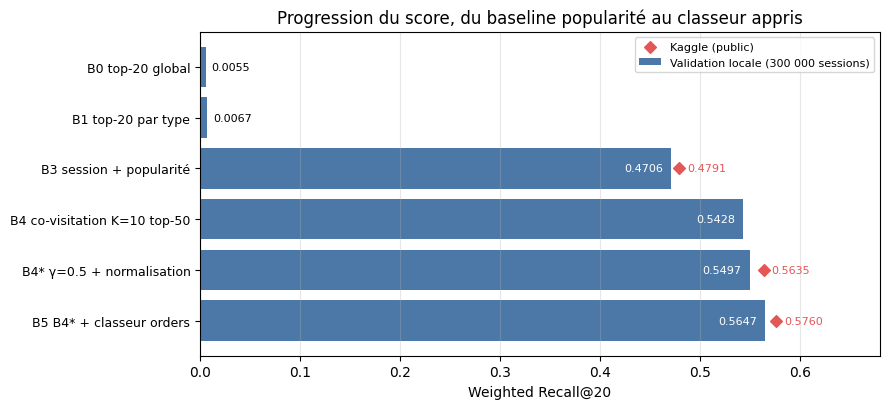

In [35]:
import matplotlib.pyplot as plt
df = pd.read_csv(RESULTS_PATH)
main = ["B0 top-20 global", "B1 top-20 par type", "B3 session + popularité", "B4 co-visitation K=10 top-50",
        "B4* γ=0.5 + normalisation", "B5 B4* + classeur orders"]
def get(m, s):
    x = df[(df.model == m) & (df.split == s)]
    return x.score.iloc[0] if len(x) else np.nan
dev = [get(m, "dev300k") for m in main]; pub = [get(m, "kaggle_public") for m in main]

fig, ax = plt.subplots(figsize=(9, 4.2)); y = np.arange(len(main))[::-1]
ax.barh(y, dev, color="#4C78A8", label="Validation locale (300 000 sessions)")
ax.scatter(pub, y, marker="D", color="#E45756", zorder=3, label="Kaggle (public)")
for yi, d, p in zip(y, dev, pub):
    if d > 0.1: ax.text(d - 0.008, yi, f"{d:.4f}", va="center", ha="right", fontsize=8, color="white")
    else:       ax.text(d + 0.006, yi, f"{d:.4f}", va="center", fontsize=8)
    if not np.isnan(p): ax.text(p + 0.008, yi, f"{p:.4f}", va="center", fontsize=8, color="#E45756")
ax.set_yticks(y); ax.set_yticklabels(main, fontsize=9); ax.set_xlim(0, 0.68)
ax.set_xlabel("Weighted Recall@20"); ax.set_title("Progression du score, du baseline popularité au classeur appris")
ax.legend(loc="upper right", fontsize=8); ax.grid(axis="x", alpha=.3); plt.tight_layout()
os.makedirs(f"{BASE}/reports/figures", exist_ok=True)
plt.savefig(f"{BASE}/reports/figures/progression_scores.png", dpi=150)
plt.show()

In [36]:
def md_table(df, models):
    f = lambda v, n=4: "n/a" if pd.isna(v) else f"{v:.{n}f}"
    def one(m, s, col):
        x = df[(df.model == m) & (df.split == s)]
        return x[col].iloc[0] if len(x) else np.nan
    lines = ["| Modèle | clicks | carts | orders | Score dev | Kaggle public | Kaggle privé |", "|---|---|---|---|---|---|---|"]
    for m in models:
        lines.append(f"| {m} | " + " | ".join(f(one(m, "dev300k", c)) for c in ("clicks", "carts", "orders", "score"))
                     + f" | {f(one(m, 'kaggle_public', 'score'), 5)} | {f(one(m, 'kaggle_private', 'score'), 5)} |")
    return "\n".join(lines)

print(md_table(pd.read_csv(RESULTS_PATH),
               ["B0 top-20 global", "B1 top-20 par type", "B3 session + popularité", "B4 co-visitation K=10 top-50",
                "B4* γ=0.5 + normalisation", "B5 B4* + classeur orders"]))

| Modèle | clicks | carts | orders | Score dev | Kaggle public | Kaggle privé |
|---|---|---|---|---|---|---|
| B0 top-20 global | 0.0082 | 0.0062 | 0.0047 | 0.0055 | n/a | n/a |
| B1 top-20 par type | 0.0082 | 0.0078 | 0.0060 | 0.0067 | n/a | n/a |
| B3 session + popularité | 0.3275 | 0.3121 | 0.5738 | 0.4706 | 0.47910 | 0.48030 |
| B4 co-visitation K=10 top-50 | 0.5028 | 0.3947 | 0.6235 | 0.5428 | n/a | n/a |
| B4* γ=0.5 + normalisation | 0.5134 | 0.4042 | 0.6285 | 0.5497 | 0.56353 | 0.56271 |
| B5 B4* + classeur orders | 0.5134 | 0.4042 | 0.6535 | 0.5647 | 0.57597 | 0.57566 |
